# Network Intrusion Detection

In [1]:
import sys
sys.path.append("..")  # so we can import the src package from the notebooks/ folder

from src.cic_data_loader import *
from src.preprocessing import *
from src.model import *
from src.evaluate import *
from src.neural_net import *
from src.compare import *
from src.tree_models import *
from src.cross_validation import *


## 1. Download and load the data

In [5]:
df = cic_load_data(data_dir="../data")

print(df.shape)
#Should be no nulls or duplicates in the dataset
display(df.isnull().sum().sum())
display(df.duplicated().sum()) 

(2563107, 80)


np.int64(0)

np.int64(0)

## 2. Split the data

In [2]:
#This is old code that was based off of splitting by day
"""
#Test set is firday by default, but can be changed to any day of the week.
train, test = split_by_day(df)

print("Training rows:", len(train))
print("Test rows:", len(test))
train.head()
"""

#This new code splits within each day by a certain fraction
train, test = split_within_days(df, test_frac=0.10)

print("Training rows:", len(train))
print("Test rows:", len(test))
train.head()

NameError: name 'df' is not defined

## 3. Prepare features

This encodes the text columns (`protocol_type`, `service`, `flag`) into numbers and scales everything, since logistic regression needs numeric, comparably-sized inputs.

In [ ]:
X_train, X_test, y_train, y_test, scaler = prepare_cic_features(train, test, drop_cols=("Label", "Day", "is_attack", "Block"))

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("Scaler:", scaler)

X_train shape: (2306452, 77)
X_test shape: (253755, 77)
y_train shape: (2306452,)
y_test shape: (253755,)
Scaler: StandardScaler()


## 4. Train the model

In [ ]:
model = train_lr_model(X_train, y_train)
print("Model trained")

/home/storm/Desktop/School Work/CSC Projects/NetworkIntrusionDetector/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


## 5. Evaluate

We look at accuracy, precision, and recall rather than just accuracy, since missing an attack is usually worse than a false alarm.

In [ ]:
y_pred = predict(model, X_test)
print_report(y_test, y_pred)

Accuracy:  0.7739
Precision: 0.9968
Recall:    0.3705

Confusion matrix (rows=actual, cols=predicted):
[[394514    263]
 [138911  81745]]

              precision    recall  f1-score   support

      normal       0.74      1.00      0.85    394777
      attack       1.00      0.37      0.54    220656

    accuracy                           0.77    615433
   macro avg       0.87      0.68      0.70    615433
weighted avg       0.83      0.77      0.74    615433



## 6. Create other models to compare

All the ones using mlp are pretty heavy.

In [ ]:
lr_model = model

models = {
    "Logistic Regression (default)": lr_model,
}


## LR Model Options

In [ ]:
# %%script false --no-raise-error
# This entire cell will be skipped during "Run All"

lr_model = train_lr_model(X_train, y_train, max_iter=2000)
models.update({"Logistic Regression (2000 iterations)": lr_model})

## MLP Model Options

In [ ]:
%%script false --no-raise-error
# This entire cell will be skipped during "Run All"

#16 nodes with 42 random states
mlp_model = train_mlp(X_train, y_train, hidden_layer_size=(16,))
models.update({"Neural Net (16 nodes)": mlp_model})

In [ ]:
%%script false --no-raise-error

#32 nodes with 42 random states
mlp_model = train_mlp(X_train, y_train, hidden_layer_size=(32,))
models.update({"Neural Net (32 nodes)": mlp_model})

In [ ]:
%%script false --no-raise-error

#64 nodes with 64 random states
mlp_model_2 = train_mlp(X_train, y_train, hidden_layer_size=(64,), random_state=64)
models.update({"Neural Net (64 nodes)": mlp_model_2})

## CURRENT BEST MLP MODEL

In [ ]:
# %%script false --no-raise-error

#two sets of 32 and 16 nodes with 42 random states
mlp_model_3 = train_mlp(X_train, y_train, hidden_layer_size=(32, 16))
models.update({"Neural Net (32-16 nodes)": mlp_model_3})

In [ ]:
%%script false --no-raise-error

#two sets of 32 and 32 nodes with 42 random states
mlp_model_3 = train_mlp(X_train, y_train, hidden_layer_size=(32, 32))
models.update({"Neural Net (32-32 nodes)": mlp_model_3})

## HGB (Tree) Model Options

In [ ]:
%%script false --no-raise-error
hgb_model = train_hgb(X_train, y_train)
models.update({"Default Tree Model (HGB)": hgb_model})

In [ ]:
%%script false --no-raise-error
# Increased Depth to 3
hgb_model_1 = train_hgb(X_train, y_train, max_depth=3)
models.update({"Tree Model (Tree Depth 3)": hgb_model_1})

In [ ]:
%%script false --no-raise-error
# Increased Depth to 3 and Number of Iterations to 200
hgb_model_1 = train_hgb(X_train, y_train, max_depth=3, max_iter=200)
models.update({"Tree Model (Tree Depth 3 and 200 Iterations)": hgb_model_1})

In [ ]:
%%script false --no-raise-error
# Increased Depth to 5 and Number of Iterations to 200
hgb_model_1 = train_hgb(X_train, y_train, max_depth=5, max_iter=200)
models.update({"Tree Model (Tree Depth 5 and 200 Iterations)": hgb_model_1})

## 7. Compare the new models

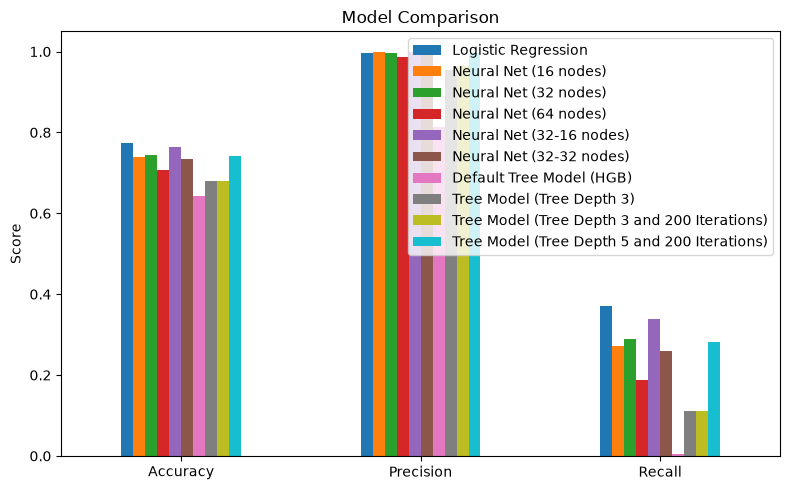

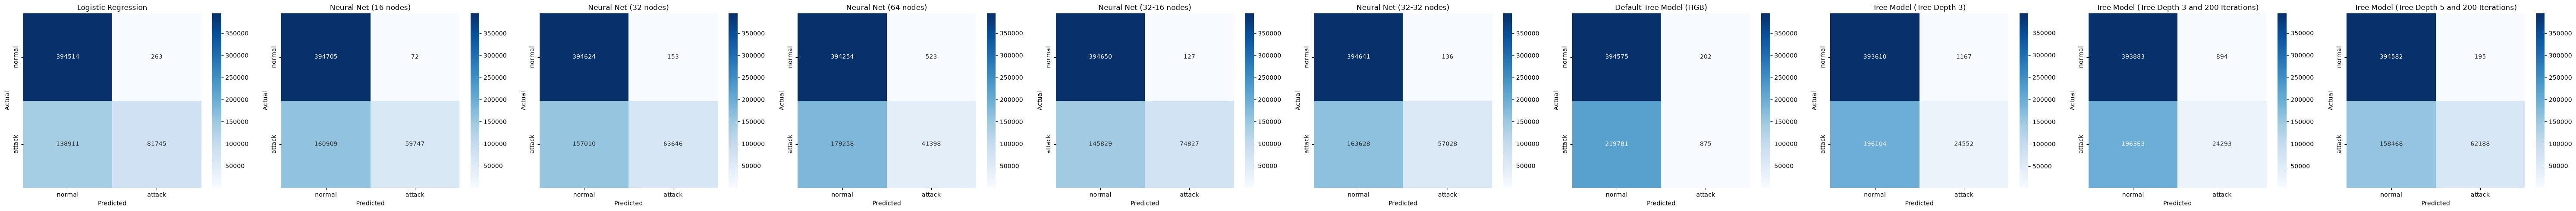

In [ ]:
results_df, confusion_matrices = compare_models(models, X_test, y_test)
# print(results_df)
plot_bar_chart(results_df, title="Model Comparison")
plot_confusion_matrices(confusion_matrices)

## 8. K-Fold Testing

Logistic Regression is done!
Neural Net (16 nodes) is done!
Neural Net (32 nodes) is done!
Neural Net (64 nodes) is done!
Neural Net (32-16 nodes) is done!
Neural Net (32-32 nodes) is done!
Default Tree Model (HGB) is done!
Tree Model (Tree Depth 3) is done!
Tree Model (Tree Depth 3 and 200 Iterations) is done!
Tree Model (Tree Depth 5 and 200 Iterations) is done!


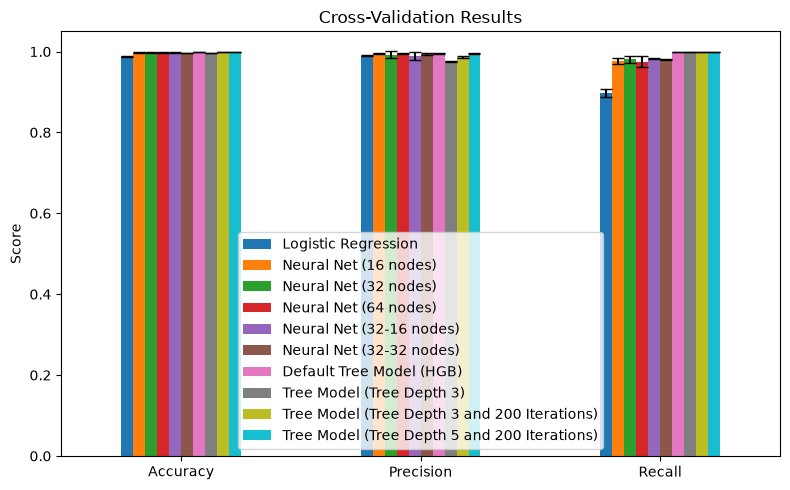

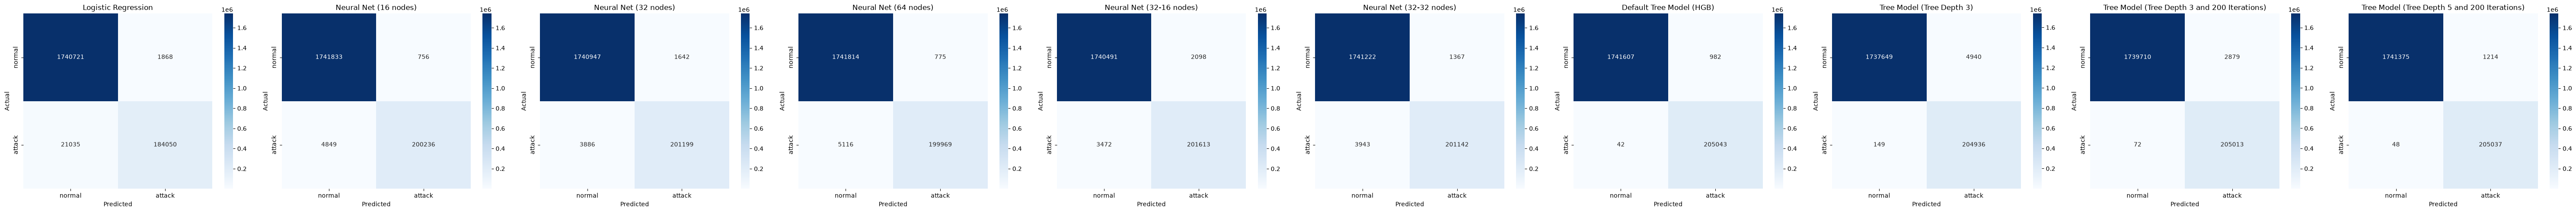

In [ ]:
from sklearn.model_selection import StratifiedKFold, GroupKFold
from src.cross_validation import *

# Plain k-fold: shuffle the rows into 5 parts, train on 4, test on 1, repeat
mean, stds, confusion_matrices = run_cv(models, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42))
plot_bar_chart(mean, title="Cross-Validation Results", errors=stds)
plot_confusion_matrices(confusion_matrices)

Logistic Regression is done!
Neural Net (16 nodes) is done!
Neural Net (32 nodes) is done!
Neural Net (64 nodes) is done!
Neural Net (32-16 nodes) is done!
Neural Net (32-32 nodes) is done!
Default Tree Model (HGB) is done!
Tree Model (Tree Depth 3) is done!
Tree Model (Tree Depth 3 and 200 Iterations) is done!
Tree Model (Tree Depth 5 and 200 Iterations) is done!


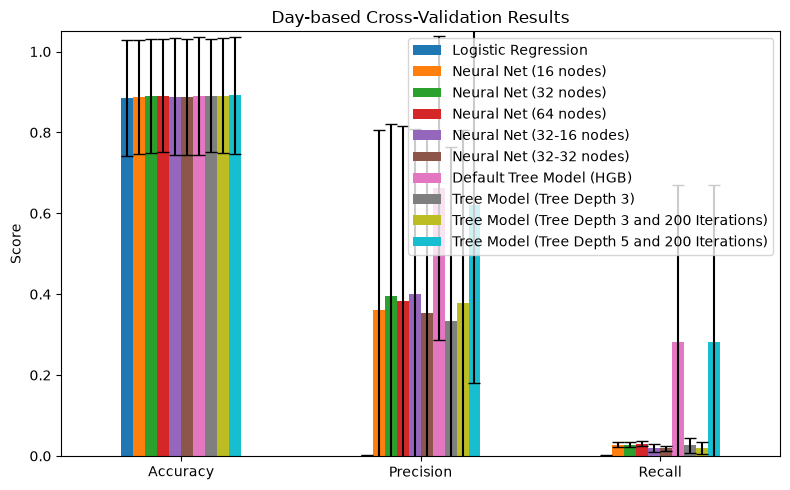

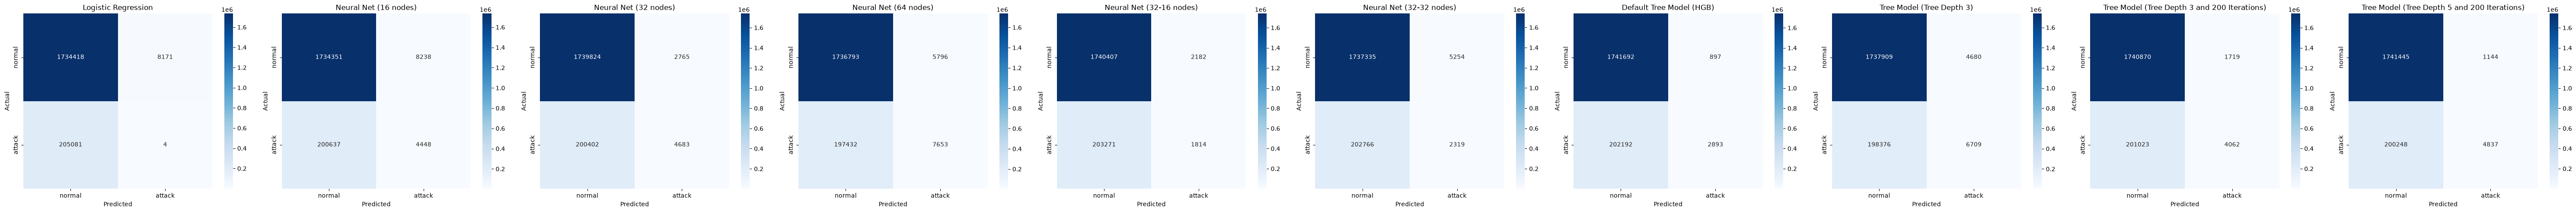

In [ ]:
from sklearn.model_selection import StratifiedKFold, GroupKFold

# Day-based: each fold holds out whole days
groups = train["Day"].replace({"monday": "tuesday"})
mean, stds, confusion_matrices = run_cv(models, X_train, y_train, cv=GroupKFold(n_splits=groups.nunique()), groups=groups)
plot_bar_chart(mean, title="Day-based Cross-Validation Results", errors=stds, path="day_cv_comparison.png")
plot_confusion_matrices(confusion_matrices, path="day_confusion_matrices.png")